# Toronto Crime Pattern Clustering and Forecasting

Analysis of Toronto Police Major Crime Indicators (MCI) data: geographic clustering (K-Means and DBSCAN), neighbourhood crime profiles (PCA), a monthly forecast compared with a seasonal-naive baseline, and an interactive map.

**Data:** download the Major Crime Indicators CSV from the Toronto Police open data portal and save it next to this notebook as `major-crime-indicators.csv`. The CSV is not included in the repository.

**Reading the results:** these only include reported incidents, and public location data is approximate. Neighbourhood charts use raw counts, not rates per person.

In [ ]:
!pip install folium scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, silhouette_score

import folium

## 1. Load and clean the data

Steps: parse the occurrence date, drop rows missing a date or coordinates, and keep incidents from 2020 onward.

In [ ]:
# Read the crime data file
df = pd.read_csv("major-crime-indicators.csv")

# Print the table's size as (number of rows, number of columns),
# then list each column with its data type and how many values are filled in.
print(df.shape)
df.info()

(452949, 29)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 452949 entries, 0 to 452948
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   _id                452949 non-null  int64  
 1   EVENT_UNIQUE_ID    452949 non-null  object 
 2   REPORT_DATE        452949 non-null  object 
 3   OCC_DATE           452949 non-null  object 
 4   REPORT_YEAR        452949 non-null  int64  
 5   REPORT_MONTH       452949 non-null  object 
 6   REPORT_DAY         452949 non-null  int64  
 7   REPORT_DOY         452949 non-null  int64  
 8   REPORT_DOW         452949 non-null  object 
 9   REPORT_HOUR        452949 non-null  int64  
 10  OCC_YEAR           452798 non-null  float64
 11  OCC_MONTH          452798 non-null  object 
 12  OCC_DAY            452798 non-null  float64
 13  OCC_DOY            452798 non-null  float64
 14  OCC_DOW            452798 non-null  object 
 15  OCC_HOUR           452949 non-null  in

In [ ]:
# Cleans the data so later steps don't break on missing or broken values.

rows_before = len(df) # remember how many rows we started with so we can report how many were removed

# Turn the date column (text) into real dates the computer can do maths with.
# errors='coerce' means: if a date can't be read, mark it as missing instead of crashing.
df['OCC_DATE'] = pd.to_datetime(df['OCC_DATE'], errors='coerce')

# Count the rows that are missing a date, latitude or longitude.
missing_required = df[['OCC_DATE', 'LAT_WGS84', 'LONG_WGS84']].isna().any(axis=1).sum()

# Remove those rows. .copy() makes a fresh, separate table so Python doesn't give warnings later.
df = df.dropna(subset=['OCC_DATE', 'LAT_WGS84', 'LONG_WGS84']).copy()
rows_after_required = len(df)

# Keep 2020 onward for the analysis
df = df[df['OCC_DATE'].dt.year >= 2020].copy()

# The most recent crime date in the data.
last_date = df['OCC_DATE'].max()

# Print a summary of what the cleaning did.
print(f"Rows in source file: {rows_before:,}")
print(f"Rows removed for missing/invalid date or coordinates: {missing_required:,}")
print(f"Rows with required fields: {rows_after_required:,}")
print(f"Rows retained from 2020 onward: {len(df):,}")
print("Date range:", df['OCC_DATE'].min().date(), "to", last_date.date())

Rows in source file: 452,949
Rows removed for missing/invalid date or coordinates: 6,680
Rows with required fields: 446,269
Rows retained from 2020 onward: 235,507
Date range: 2020-01-01 to 2025-09-30


## 2. Exploratory analysis

The data ends part-way through the final year, so the first chart labels that year as partial and the second compares the same calendar period (Jan 1 to the last date in the data) across years.

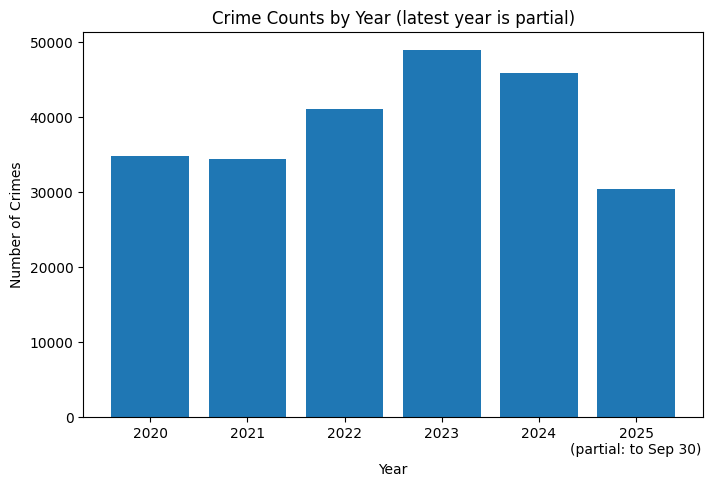

In [ ]:
# Explore the data with simple charts.

# Add a column holding the year each crime happened.
df['YEAR'] = df['OCC_DATE'].dt.year

# Count how many crimes happened in each year.
yearly = df.groupby('YEAR').size()

# Make the labels for the bottom of the chart (one per year).
labels = [str(y) for y in yearly.index]
# If the data doesn't run to December 31, mark the last year as "partial"
# so nobody mistakes an incomplete year for a drop in crime.
if not (last_date.month == 12 and last_date.day == 31):
    labels[-1] = f"{yearly.index[-1]}\n(partial: to {last_date.strftime('%b %d')})"

# Draw a bar chart with one bar per year.
plt.figure(figsize=(8, 5))                  # chart size
plt.bar(range(len(yearly)), yearly.values)  # bar heights = number of crimes
plt.xticks(range(len(yearly)), labels)      # put the year labels under the bars
plt.title("Crime Counts by Year (latest year is partial)")
plt.xlabel("Year")
plt.ylabel("Number of Crimes")
plt.show()

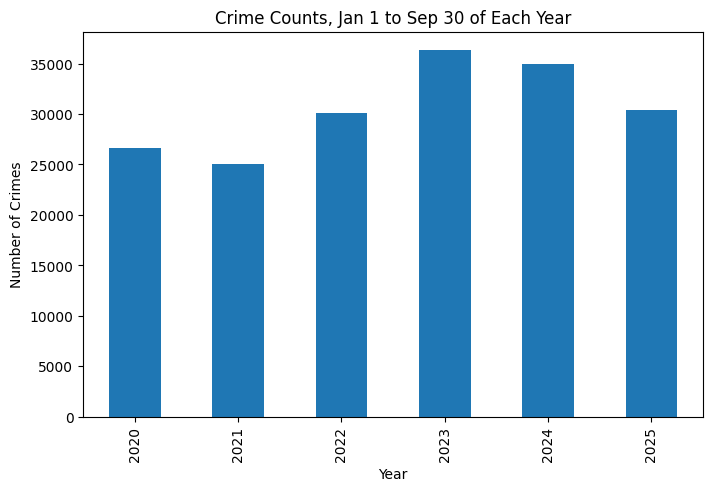

In [ ]:
# Like-for-like comparison: Jan 1 to the same month/day in every year
same_period = df[
    (df['OCC_DATE'].dt.month < last_date.month)
    | ((df['OCC_DATE'].dt.month == last_date.month) & (df['OCC_DATE'].dt.day <= last_date.day))
]

# Count per year and draw a bar chart.
same_period.groupby('YEAR').size().plot(kind='bar', figsize=(8, 5))
plt.title(f"Crime Counts, Jan 1 to {last_date.strftime('%b %d')} of Each Year")
plt.xlabel("Year")
plt.ylabel("Number of Crimes")
plt.show()

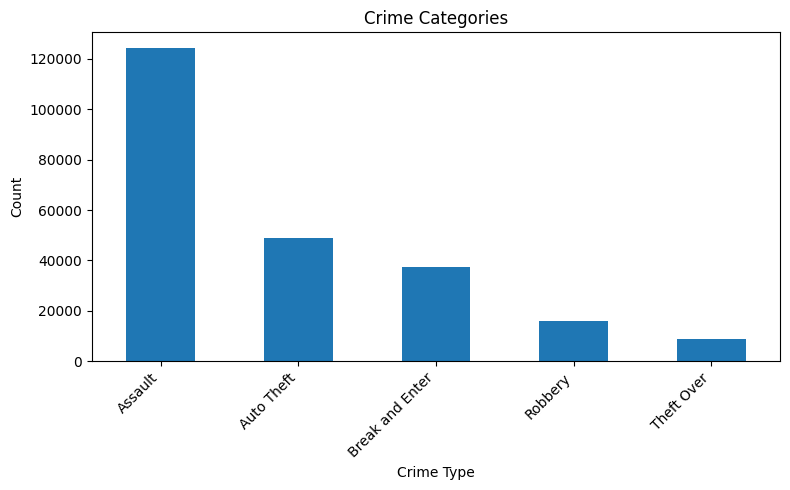

In [ ]:
# Count how many crimes fall into each category (assault, auto theft, etc.) and chart them.
df['MCI_CATEGORY'].value_counts().plot(kind='bar', figsize=(8, 5))
plt.title("Crime Categories")
plt.xlabel("Crime Type")
plt.ylabel("Count")
plt.xticks(rotation=45, ha='right')   # tilt the labels so they don't overlap
plt.tight_layout()                    # adjust spacing so nothing is cut off
plt.show()

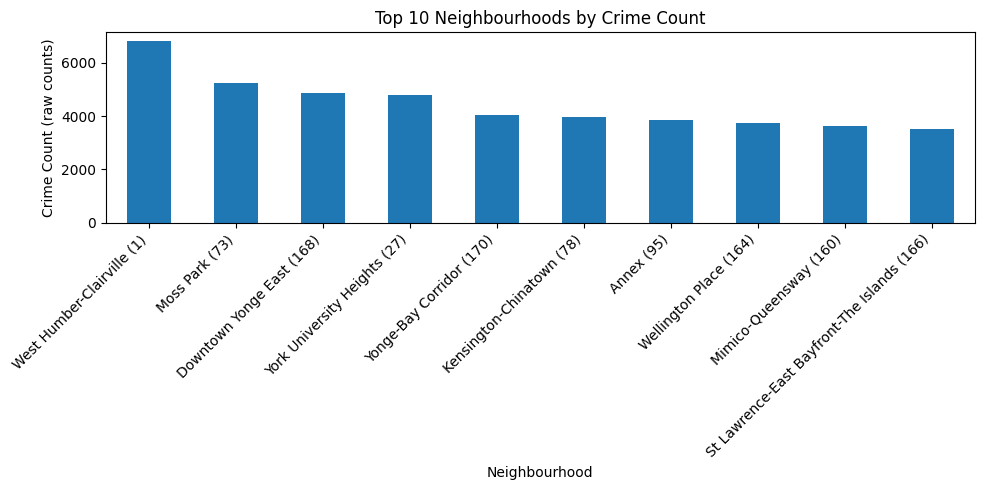

In [ ]:
# Find the 10 neighbourhoods with the most recorded crimes.
# These are raw counts, so busier or more populated areas naturally rank higher.
top_neighbourhoods = df['NEIGHBOURHOOD_158'].value_counts().head(10)

top_neighbourhoods.plot(kind='bar', figsize=(10, 5))
plt.title("Top 10 Neighbourhoods by Crime Count")
plt.xlabel("Neighbourhood")
plt.ylabel("Crime Count (raw counts)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 3. Geographic clustering

Latitude and longitude are standardized before clustering so both axes have comparable influence. K-Means divides the city into a chosen number of geographic groups; DBSCAN identifies dense groups and labels points outside them as noise.

These geographic groupings are purely exploratory. The source coordinates are approximate/offset for privacy and can appear aligned along street segments.

In [ ]:
# Group crimes by location. First, prepare the location data.

# Take just the two location columns: latitude (north-south) and longitude (east-west).
coords = df[['LAT_WGS84', 'LONG_WGS84']]

# Rescale both columns to the same scale so neither one counts for more than the other.
coords_scaled = StandardScaler().fit_transform(coords)

### K-Means: choosing the number of clusters

K-Means needs the number of clusters in advance. The elbow plot shows how inertia falls as k increases; the silhouette score (calculated on a fixed 10,000-point sample) measures how well-separated the groups are.

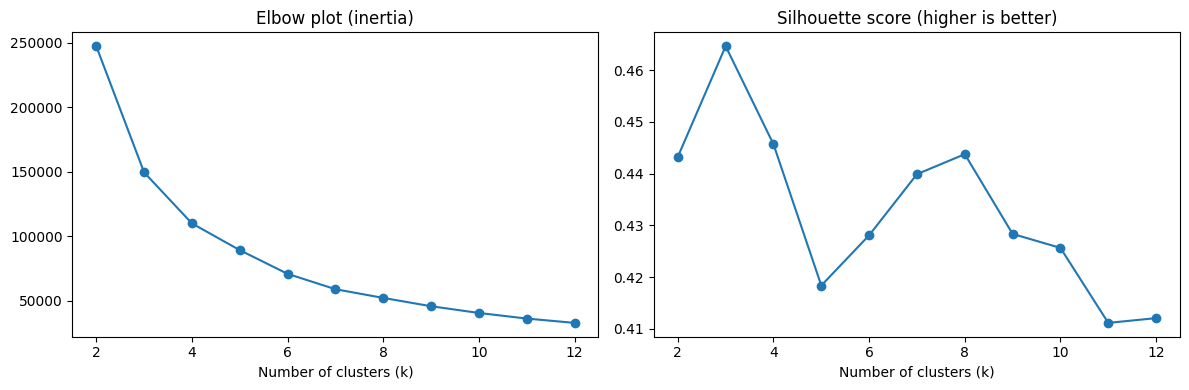

In [ ]:
# To help choose k, try every value from 2 to 12 and score each one two ways:
#   - inertia ("elbow plot"): how tightly packed each group is; lower = tighter
#   - silhouette score: how well separated the groups are from each other; higher = better

# Pick 10,000 random crimes to score with. Scoring all of them would be very slow.
# The fixed seed (42) makes the "random" pick identical every time.
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(coords_scaled), size=min(10000, len(coords_scaled)), replace=False)

ks = list(range(2, 13))       # the group counts to try: 2, 3, ..., 12
inertias, sil_scores = [], [] # empty lists to store the scores
for k in ks:
    # Group all the points into k clusters.
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(coords_scaled)
    # Save how tight the groups are, and how well separated they are.
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(coords_scaled[sample_idx], km.labels_[sample_idx]))

# Draw the two score charts side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertias, marker='o')
axes[0].set_title("Elbow plot (inertia)")
axes[0].set_xlabel("Number of clusters (k)")
axes[1].plot(ks, sil_scores, marker='o')
axes[1].set_title("Silhouette score (higher is better)")
axes[1].set_xlabel("Number of clusters (k)")
plt.tight_layout()
plt.show()

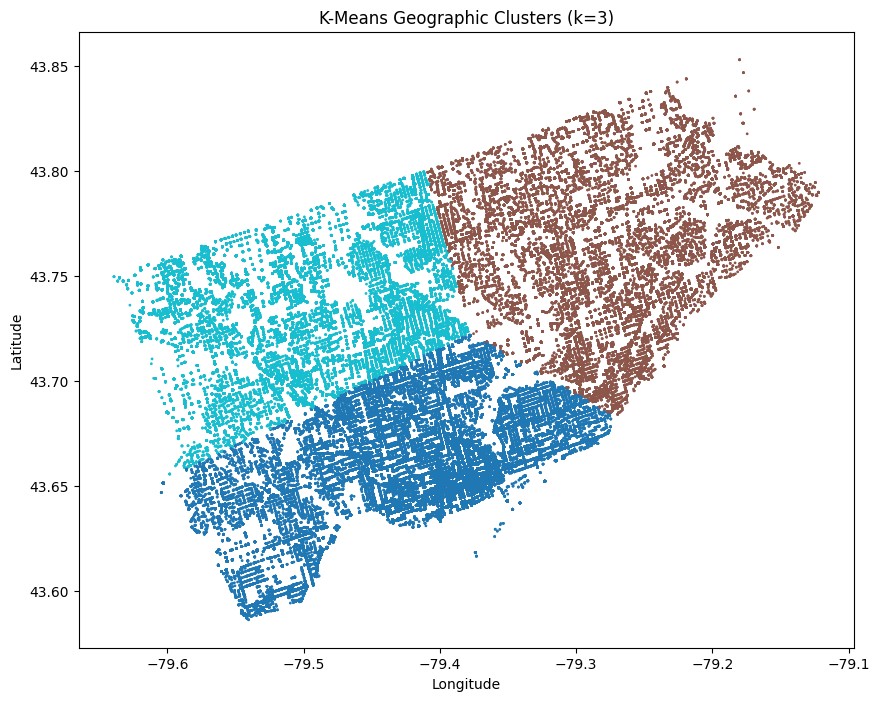

,count
kmeans_cluster,
0,113321
1,60486
2,61700


In [ ]:
# Choose k and build the final K-Means grouping.
K = 3  # highest silhouette score among the tested values (k=2 to 12)

# Group every crime into K clusters based on location and store each crime's group number in a new column.
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
df['kmeans_cluster'] = kmeans.fit_predict(coords_scaled)

# Draw a map-like scatter plot: one dot per crime, coloured by its group.
plt.figure(figsize=(10, 8))
plt.scatter(df['LONG_WGS84'], df['LAT_WGS84'], c=df['kmeans_cluster'], cmap='tab10', s=1)
plt.title(f"K-Means Geographic Clusters (k={K})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

# Show how many crimes ended up in each group.
df['kmeans_cluster'].value_counts().sort_index()

**K-Means selection:** k=3 had the highest sampled silhouette score (0.4646) among the tested values. It divides the incidents into three broad geographic groups based on spatial partitions.

### DBSCAN: finding dense areas

DBSCAN groups points that are close together and labels isolated points as noise (`-1`). The `eps` values below are in standardized coordinate units, because the latitude/longitude columns were scaled in the previous cell

The settings table compares the original values with smaller neighbourhood radii and larger minimum cluster sizes. The cluster count and largest-cluster share help show whether one dense area dominates the result. The larger `min_samples` tests are included to see whether they produce a shorter list of larger dense groups, while noting how much data they leave unclustered.

In [ ]:
settings = [
    (0.03, 20),    # (eps, min_samples) pairs to compare; this first one is the loosest
    (0.01, 50),    # the setting used for the final map below
    (0.01, 100),
    (0.005, 50),
    (0.01, 200),   # stricter density requirement
    (0.01, 500),   # very strict density requirement
]

rows = []
for eps, min_s in settings:
    # Run DBSCAN; each crime gets a group number, or -1 if it is noise.
    lab = DBSCAN(eps=eps, min_samples=min_s).fit_predict(coords_scaled)
    clustered_labels = lab[lab != -1]               # leave out the noise points
    n_clusters = len(np.unique(clustered_labels))   # count the distinct groups found
    # Record three facts about this run.
    rows.append({
        'eps': eps,
        'min_samples': min_s,
        'clusters': n_clusters,
        'noise %': round(100 * (lab == -1).mean(), 1),   # share of crimes not in any group
        'largest cluster % of clustered points': (       # how much of the grouped data the biggest group holds
            round(100 * pd.Series(clustered_labels).value_counts(normalize=True).iloc[0], 1)
            if n_clusters else np.nan
        ),
    })

# Show the results as a table.
pd.DataFrame(rows)

,eps,min_samples,clusters,noise %,largest cluster % of clustered points
0,0.030,20,765,2.5,45.6
1,0.010,50,977,54.7,2.2
2,0.010,100,332,73.7,3.9
3,0.005,50,926,59.1,2.5
4,0.010,200,83,88.0,8.5
5,0.010,500,11,96.3,27.1


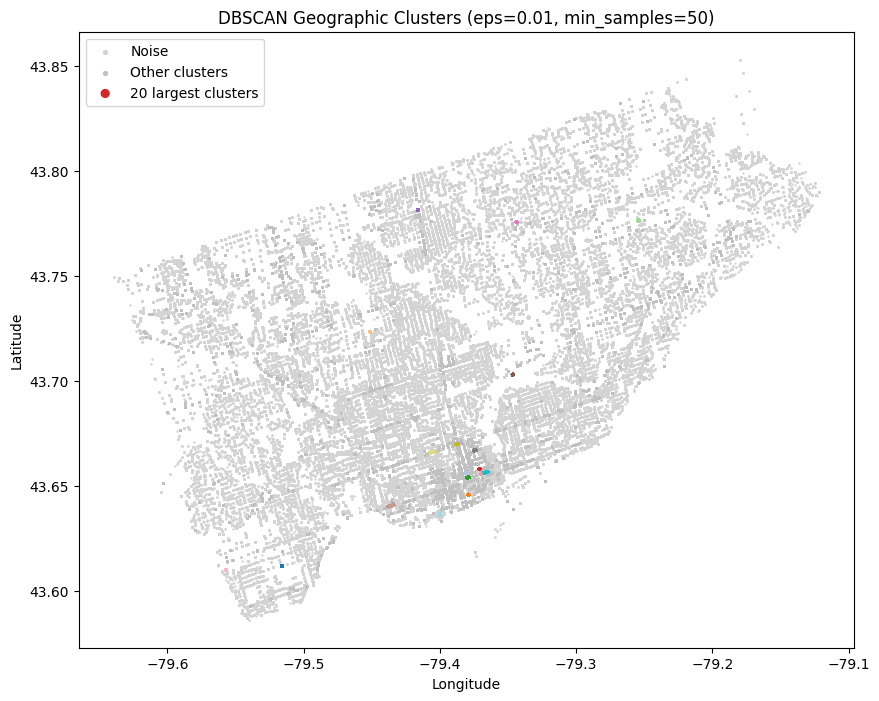

977 clusters, 54.7% of points labelled noise
The 20 largest clusters are highlighted; other clusters and noise are grey.


In [ ]:
# Run DBSCAN once more with the chosen settings and map the result.
EPS, MIN_SAMPLES = 0.01, 50  # stricter settings label most incidents as noise

# Store each crime's group number (or -1 for noise) in a new column.
df['dbscan_cluster'] = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(coords_scaled)

# Split the table into crimes that are noise and crimes that are in a group.
noise = df[df['dbscan_cluster'] == -1]
clustered = df[df['dbscan_cluster'] != -1]

# Highlight only the 20 largest clusters with distinct colours.
# All remaining clusters and noise points are grey, so colours are not reused
# to imply that unrelated clusters belong together.
top_cluster_ids = clustered['dbscan_cluster'].value_counts().head(20).index
top_cluster_points = clustered[clustered['dbscan_cluster'].isin(top_cluster_ids)]
other_cluster_points = clustered[~clustered['dbscan_cluster'].isin(top_cluster_ids)]

# Draw three layers: noise in light grey, small clusters in silver, big clusters in colour.
plt.figure(figsize=(10, 8))
plt.scatter(noise['LONG_WGS84'], noise['LAT_WGS84'],
            c='lightgrey', s=0.5, label='Noise')
plt.scatter(other_cluster_points['LONG_WGS84'], other_cluster_points['LAT_WGS84'],
            c='silver', s=0.5, label='Other clusters')
plt.scatter(top_cluster_points['LONG_WGS84'], top_cluster_points['LAT_WGS84'],
            c=top_cluster_points['dbscan_cluster'].map(                          # give each big cluster its own colour number (0-19)
                {cluster_id: i for i, cluster_id in enumerate(top_cluster_ids)}
            ),
            cmap='tab20', vmin=0, vmax=19, s=2, label='20 largest clusters')

plt.title(f"DBSCAN Geographic Clusters (eps={EPS}, min_samples={MIN_SAMPLES})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(markerscale=4)   # make the legend dots big enough to see
plt.show()

# Print how many groups were found and how much of the data was left out as noise.
print(f"{clustered['dbscan_cluster'].nunique()} clusters, "
      f"{100 * len(noise) / len(df):.1f}% of points labelled noise")
print("The 20 largest clusters are highlighted; other clusters and noise are grey.")

In [ ]:
# Ten largest DBSCAN clusters: size, centre point, and most common neighbourhood
top_clusters = (
    clustered.groupby('dbscan_cluster')                                        # work on each group separately
    .agg(incidents=('OCC_DATE', 'size'),                                       # number of crimes in the group
         lat=('LAT_WGS84', 'mean'),                                            # average latitude = the centre
         lon=('LONG_WGS84', 'mean'),                                           # average longitude
         main_neighbourhood=('NEIGHBOURHOOD_158', lambda s: s.mode().iat[0]))  # most common neighbourhood name
    .sort_values('incidents', ascending=False)                                 # biggest groups first
    .head(10)                                                                  # keep the top 10
)
top_clusters

,incidents,lat,lon,main_neighbourhood
dbscan_cluster,,,,
44,2391,43.612080,-79.515814,Mimico-Queensway (160)
98,821,43.656325,-79.380913,Downtown Yonge East (168)
28,795,43.645930,-79.379093,St Lawrence-East Bayfront-The Islands (166)
110,715,43.723657,-79.451306,Yorkdale-Glen Park (31)
77,669,43.654122,-79.379708,Yonge-Bay Corridor (170)
63,630,43.776638,-79.254239,Bendale-Glen Andrew (156)
24,626,43.658297,-79.371003,Moss Park (73)
93,574,43.656163,-79.370099,Moss Park (73)
222,550,43.781633,-79.415990,Newtonbrook West (36)


## 4. Neighbourhood crime patterns (PCA)

Each neighbourhood is a row and each crime category is a feature. Category counts are standardized across neighbourhoods before PCA, putting categories on comparable scales. This does not remove the influence of overall crime volume,  PC1 may therefore capture a shared higher/lower count pattern across categories, while later components can distinguish differences in crime-category composition.

The labels identify the eight neighbourhoods furthest from the origin in the first two components.

In [ ]:
# Compare neighbourhoods by the mix of crimes they have (PCA).
# PCA takes many columns (one per crime category) and boils them down to two summary numbers
# per neighbourhood, so every neighbourhood can be shown as one dot on a chart.

# Build a table with one row per neighbourhood and one column per crime category,
# where each cell is the number of crimes of that type in that neighbourhood.
crime_pivot = pd.pivot_table(
    df,
    index='NEIGHBOURHOOD_158',
    columns='MCI_CATEGORY',
    aggfunc='size',      # "size" = count the rows
    fill_value=0         # if a neighbourhood has none of a category, show 0
)

# Put each category's counts on the same scale, then squeeze them down to 2 numbers per neighbourhood.
scaled = StandardScaler().fit_transform(crime_pivot)

pca = PCA(n_components=2)
components = pca.fit_transform(scaled)

# How much of the original information the 2 numbers keep (closer to 100% = less is lost).
print("Explained variance ratio (PC1, PC2):", pca.explained_variance_ratio_.round(3))
# Loadings show which crime categories push each of the 2 numbers up or down.
print("\nLoadings (how much each crime category contributes to each component):")
print(pd.DataFrame(pca.components_.T, index=crime_pivot.columns, columns=['PC1', 'PC2']).round(2))

Explained variance ratio (PC1, PC2): [0.722 0.171]

Loadings (how much each crime category contributes to each component):
                  PC1   PC2
MCI_CATEGORY               
Assault          0.44 -0.49
Auto Theft       0.33  0.82
Break and Enter  0.47 -0.17
Robbery          0.49 -0.16
Theft Over       0.49  0.21


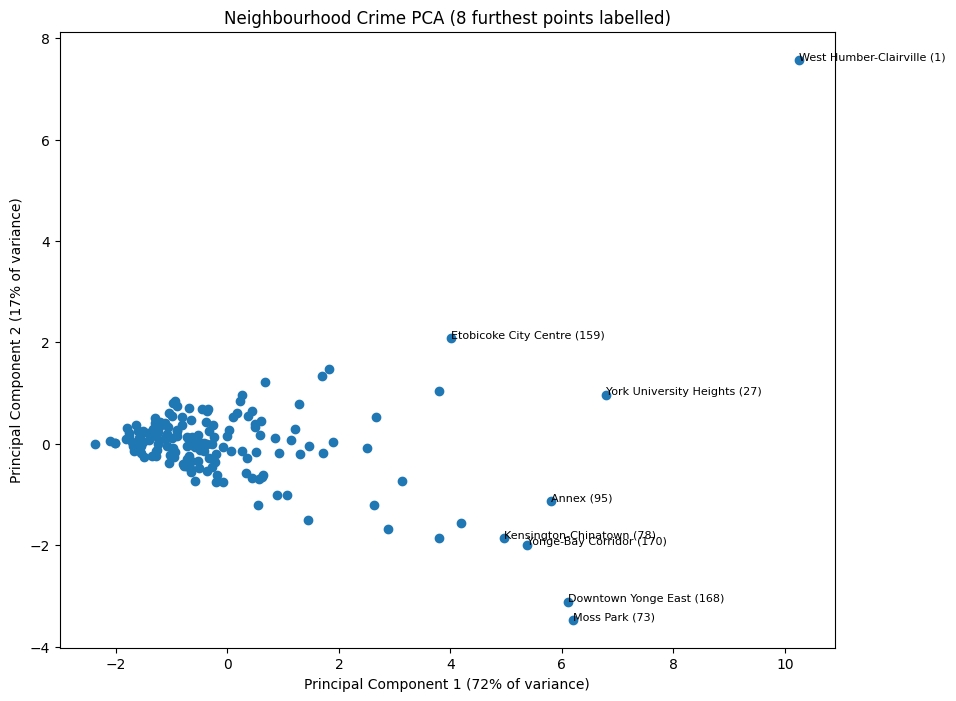

MCI_CATEGORY,Assault,Auto Theft,Break and Enter,Robbery,Theft Over
NEIGHBOURHOOD_158,,,,,
Etobicoke City Centre (159),1203,1107,426,190,257
Kensington-Chinatown (78),2511,221,755,267,201
Yonge-Bay Corridor (170),2656,166,653,324,237
Annex (95),2104,329,889,265,275
York University Heights (27),2148,1243,790,350,251
Downtown Yonge East (168),3353,214,674,482,144
Moss Park (73),3604,249,826,451,103
West Humber-Clairville (1),1654,3561,802,391,385


In [ ]:
# Find the 8 neighbourhoods that sit furthest from the centre of the chart.
# These are the most unusual compared with the rest.
dist = np.hypot(components[:, 0], components[:, 1])   # distance from the centre (0, 0) for each neighbourhood
outlier_idx = np.argsort(dist)[-8:]                   # positions of the 8 largest distances

# Plot every neighbourhood as a dot, and write the names of the 8 outliers next to their dots.
plt.figure(figsize=(10, 8))
plt.scatter(components[:, 0], components[:, 1])
for i in outlier_idx:
    plt.annotate(crime_pivot.index[i], (components[i, 0], components[i, 1]), fontsize=8)

plt.title("Neighbourhood Crime PCA (8 furthest points labelled)")
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.show()

# Show the crime counts for those 8 neighbourhoods.
crime_pivot.iloc[outlier_idx]

**How to read this result:** crime-category counts are standardized across neighbourhoods before PCA. This puts categories on comparable scales but does not remove the influence of overall crime volume. PC1's positive loadings across all five categories suggest it captures a shared higher/lower count pattern. PC2 can help distinguish differences in crime-category composition.

## 5. Forecasting monthly crime counts

The model predicts monthly incident counts using calendar features and is evaluated on the final 12 complete months. The seasonal-naive baseline predicts each month using the count from the same month one year earlier.

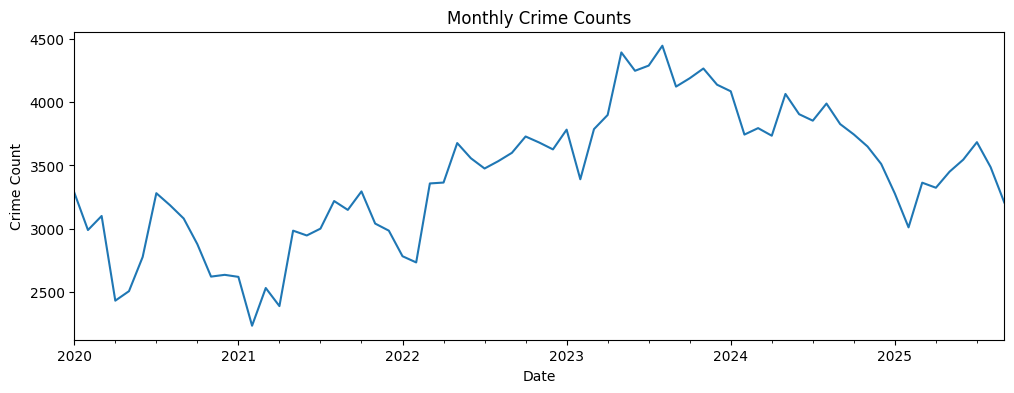

In [ ]:
# Forecast the number of crimes per month.
# Count crimes in each month. 'ME' means "month end": each month becomes one row.

monthly = (
    df.groupby(pd.Grouper(key='OCC_DATE', freq='ME'))
    .size()
    .reset_index(name='crime_count')
)

# Drop the final month if the data stops before the month ends (a partial month would look like a drop)
if last_date != last_date + pd.offsets.MonthEnd(0):
    monthly = monthly.iloc[:-1]
    print("Dropped the final partial month.")

# Add columns the prediction model can learn from: month number (1-12), year, and quarter (1-4).
monthly['month'] = monthly['OCC_DATE'].dt.month
monthly['year'] = monthly['OCC_DATE'].dt.year
monthly['quarter'] = monthly['OCC_DATE'].dt.quarter

# Draw the monthly counts over time as a line.
monthly.plot(x='OCC_DATE', y='crime_count', figsize=(12, 4), legend=False)
plt.title("Monthly Crime Counts")
plt.xlabel("Date")
plt.ylabel("Crime Count")
plt.show()

In [ ]:
# Test how well we can predict the future.
# Hide the most recent 12 months, build the model using only the earlier months,
# then compare its predictions with what really happened.
train = monthly[:-12]  # everything except the last 12 months: used to teach the model
test = monthly[-12:]   # the last 12 months: kept hidden to check the predictions

features = ['month', 'year', 'quarter']                  # the clues the model uses
X_train, y_train = train[features], train['crime_count'] # X = the clues, y = the answer (crime count)
X_test, y_test = test[features], test['crime_count']

# Model A: linear regression on calendar features (the original model)
model = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])
model.fit(X_train, y_train)
pred_model = model.predict(X_test)

# Model B: seasonal naive baseline (same month one year earlier)
pred_baseline = monthly['crime_count'].shift(12).iloc[-12:].values

# A helper function that scores a set of predictions against the real values.
def score(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)   # MAE = average size of the miss, in crimes per month
    return {
        'model': name,
        'MAE': round(mae, 1),
        'MAE as % of average month': round(100 * mae / y_true.mean(), 1),               # the miss as a share of a typical month
        'mean signed error': round(float((y_pred - y_true).mean()), 1),                 # positive = predictions too high on average
        'average error direction': 'over-predicts' if (y_pred - y_true).mean() > 0 else 'under-predicts',
    }

# Score both models and show them in one table.
pd.DataFrame([
    score('Linear regression (month, year, quarter)', y_test, pred_model),
    score('Seasonal naive (same month last year)', y_test, pred_baseline),
])

,model,MAE,MAE as % of average month,mean signed error,average error direction
0,"Linear regression (month, year, quarter)",958.3,27.9,958.3,over-predicts
1,Seasonal naive (same month last year),527.8,15.3,527.8,over-predicts


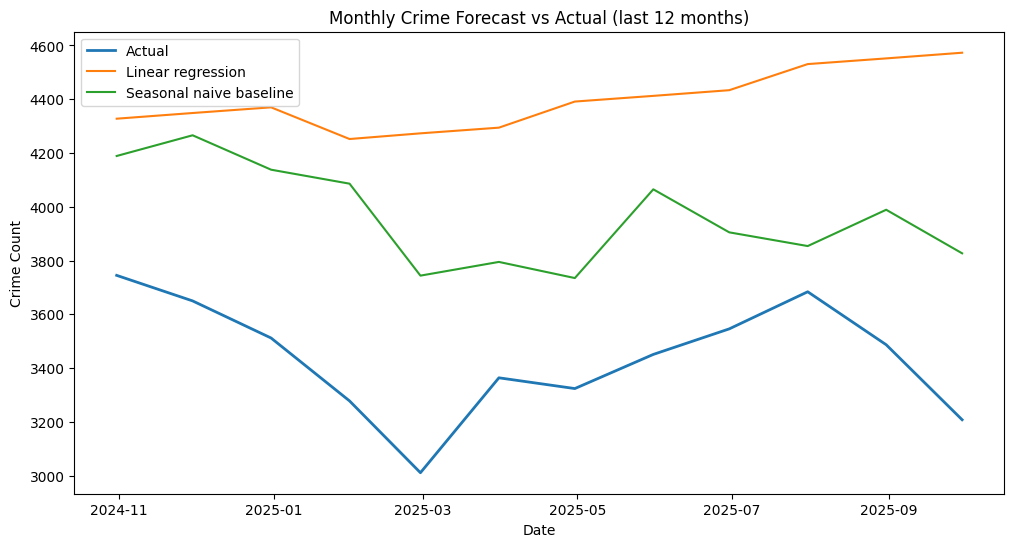

In [ ]:
# Draw the real crime counts and both models' predictions for the last 12 months on one chart,
# so you can see how close each one gets.
plt.figure(figsize=(12, 6))
plt.plot(test['OCC_DATE'], y_test, label='Actual', linewidth=2)
plt.plot(test['OCC_DATE'], pred_model, label='Linear regression')
plt.plot(test['OCC_DATE'], pred_baseline, label='Seasonal naive baseline')

plt.title("Monthly Crime Forecast vs Actual (last 12 months)")
plt.xlabel("Date")
plt.ylabel("Crime Count")
plt.legend()
plt.show()

## 6. Interactive map

A random sample of 3,000 incidents (fixed seed so the map is reproducible). Hover over a point to see its category and date. The map is also saved as `crime_map.html`.

In [26]:
# Make an interactive map you can zoom and hover over.

# Start a blank map centred on Toronto (latitude 43.7, longitude -79.4).
toronto_map = folium.Map(location=[43.7, -79.4], zoom_start=11, tiles=None)

colours = {
    'Assault': 'red',
    'Auto Theft': 'blue',
    'Break and Enter': 'green',
    'Robbery': 'orange',
    'Theft Over': 'purple',
}

# Pick 3,000 random crimes because plotting all 235,000+ would make the map too heavy.
# random_state=42 makes the "random" pick the same every time.
sample_df = df.sample(3000, random_state=42)

# Add one small dot per sampled crime. Hovering over a dot shows its category and date.
for _, row in sample_df.iterrows():
    folium.CircleMarker(
        location=[row['LAT_WGS84'], row['LONG_WGS84']],
        radius=2,
        color=colours.get(row['MCI_CATEGORY'], 'gray'),
        fill=True,
        tooltip=f"{row['MCI_CATEGORY']} ({row['OCC_DATE'].date()})"
    ).add_to(toronto_map)

# A small legend in the corner
legend_html = '<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; background: white; padding: 8px 10px; border: 1px solid grey; font-size: 13px;">' + ''.join(
    f'<div><span style="color:{c}">&#9679;</span> {name}</div>' for name, c in colours.items()
) + '</div>'
toronto_map.get_root().html.add_child(folium.Element(legend_html))

# Save the map as a web page file so it can be opened on its own, then display it here.
toronto_map.save("crime_map.html")
toronto_map

## Findings and limitations

### Data
- Source file contained **452,949 rows**.
- **6,680 rows** were removed because the occurrence date or coordinates were missing/invalid, leaving 446,269 rows with the required fields.
- A further **210,762 rows** were excluded because they occurred before January 1, 2020.
- Analysis retained **235,507 incidents** from **2020-01-01 to 2025-09-30**.
- 2025 is partial (January–September). The like-for-like chart compares January 1–September 30 across all years.

### K-Means
- Selected **k=3** because it had the highest sampled silhouette score among k=2–12 (**0.4646**).
- Cluster sizes: 113,321; 60,486; and 61,700 incidents.
- Three clusters provide a coarse, broad geographic partition of Toronto. This is a metric-supported exploratory choice, not proof that three is the uniquely correct number of geographic groups or a measure of crime risk.

### DBSCAN
- The original setting (**eps=0.03, min_samples=20**) produced 765 clusters, 2.5% noise, and one cluster containing 45.6% of clustered incidents.
- With **eps=0.01, min_samples=50**, the result is 977 clusters and 54.7% noise; the largest cluster contains 2.2% of clustered incidents.
- Stricter settings at **min_samples=100, 200, and 500** produce 332, 83, and 11 clusters, respectively, but classify 73.7%, 88.0%, and 96.3% of incidents as noise.
- The displayed setting (**eps=0.01, min_samples=50**) is retained as an exploratory compromise rather than presented as definitive hotspot detection. The map highlights only the 20 largest clusters with distinct colours; other clusters and noise are grey.
- `eps` is measured in standardized coordinate units, not metres or degrees.

### PCA
- PC1 explains **72.2%** of variance and PC2 explains **17.1%** (89.3% combined).
- Category counts are standardized across neighbourhoods before PCA. This puts categories on comparable scales but does not remove overall crime-volume effects.
- PC1's positive loadings across all five categories suggest a shared higher/lower count pattern; PC2 distinguishes aspects of crime-category composition.
- The eight furthest neighbourhoods are named Toronto neighbourhoods; the most distant is **West Humber-Clairville (1)**. No `NSA` entry appears among these eight.
- These are differences in standardized category counts, not per-capita rates or direct measures of neighbourhood safety.

### Forecast
- Test period: **October 2024–September 2025**; average actual month: **3,438 incidents**.
- Linear regression MAE: **958.3 incidents (27.9%)**; mean signed error **+958.3**, so it over-predicted on average throughout this test period.
- Seasonal-naive baseline MAE: **527.8 incidents (15.3%)**; mean signed error **+527.8**, also over-predicting on average.
- The seasonal-naive baseline performed better than the regression. The regression extrapolated the earlier upward pattern and did not adapt well to the later decline.

### Limitations
- Neighbourhood charts use raw counts, not population-adjusted rates.
- Public incident locations are approximate/offset and can appear aligned along street segments; they should not be treated as exact incident locations.
- K-Means and DBSCAN use coordinates only. They do not account for population, land use, reporting differences, or exposure.
- The forecast comparison uses one 12-month holdout period. Results may differ with another test period, and the seasonal-naive baseline is a simple benchmark rather than a sophisticated forecasting model.